# Health Insurance Cross-Sell — Propensity to Buy

**Business Problem:**  
A health insurance company wants to expand into car insurance (cross-sell strategy).  
The commercial team can only call **2,000 clients** out of ~200,000.  
The goal is to **rank clients by purchase propensity** so the team contacts the most likely buyers first.

**Solution Strategy:**  
Train a ML model on a labeled dataset → generate purchase probabilities → rank clients → build Cumulative Gain & Lift curves to evaluate ranking quality.

---
## 0. Imports

In [1]:
import numpy  as np
import pandas as pd
import pickle

import seaborn as sns
from matplotlib import pyplot as plt

from sklearn import preprocessing   as pp
from sklearn import linear_model    as lm
from sklearn import model_selection as ms
from sklearn import ensemble        as en
from sklearn import neighbors       as nh

import warnings
warnings.filterwarnings('ignore')

---
## 1. Helper Functions

In [2]:
def can_convert_to_int(df, col):
    """Returns True if all non-null values in a float column are whole numbers (e.g. 3.0, 7.0)."""
    return df[col].dropna().apply(lambda x: x == int(x)).all()


def is_binary(df, col):
    """Returns True if the column has exactly 2 unique values."""
    return df[col].nunique() == 2


def is_yes_no(df, col):
    """Returns True if the column contains only 'yes' / 'no' values (case-insensitive)."""
    unique_vals = set(df[col].str.lower().unique())
    return unique_vals == {'yes', 'no'}


def encode_binary(df, col):
    """Encodes a binary column as 0/1. 'yes' → 1, 'no' → 0 when applicable."""
    if is_yes_no(df, col):
        df[col] = df[col].str.lower().map({'yes': 1, 'no': 0})
    else:
        df[col] = df[col].map({df[col].unique()[0]: 0, df[col].unique()[1]: 1})


def plot_cumulative_gain(y_true, yhats: dict):
    """
    Plots the Cumulative Gain curve for one or more models.
    yhats: dict  {model_name: predict_proba output (n x 2)}
    Interpretation: 'If I call X% of the base, I capture Y% of all interested clients.'
    """
    df_base = pd.DataFrame({'y_true': y_true})
    total_positive = df_base['y_true'].sum()
    total = len(df_base)

    plt.figure(figsize=(12, 6))

    for name, y_prob in yhats.items():
        df = df_base.copy()
        df['y_prob'] = y_prob[:, 1]
        df = df.sort_values('y_prob', ascending=False).reset_index(drop=True)
        df['cumulative_gain'] = df['y_true'].cumsum() / total_positive
        df['pct_base'] = (df.index + 1) / total
        plt.plot(df['pct_base'], df['cumulative_gain'], label=name)

    plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Random Model')
    plt.plot([0, total_positive / total, 1], [0, 1, 1], color='green', linestyle='--', label='Perfect Model')
    plt.xlabel('% of Base Contacted')
    plt.ylabel('% of Interested Clients Captured')
    plt.title('Cumulative Gain Curve')
    plt.legend()
    plt.grid(True)
    plt.show()


def plot_lift_curve(y_true, yhats: dict):
    """
    Plots the Lift curve for one or more models (starting from 10% of base to reduce noise).
    yhats: dict  {model_name: predict_proba output (n x 2)}
    Interpretation: 'My model is X times better than random when calling Y% of the base.'
    """
    df_base = pd.DataFrame({'y_true': y_true})
    total_positive = df_base['y_true'].sum()
    total = len(df_base)
    base_rate = total_positive / total

    plt.figure(figsize=(12, 6))

    for name, y_prob in yhats.items():
        df = df_base.copy()
        df['y_prob'] = y_prob[:, 1]
        df = df.sort_values('y_prob', ascending=False).reset_index(drop=True)
        df['cumulative_positive'] = df['y_true'].cumsum()
        df['pct_base'] = (df.index + 1) / total
        df['lift'] = (df['cumulative_positive'] / (df.index + 1)) / base_rate
        df = df[df['pct_base'] >= 0.1]  # removes early noise
        plt.plot(df['pct_base'], df['lift'], label=name)

    plt.axhline(y=1, color='red', linestyle='--', label='Random Model (lift = 1)')
    plt.xlabel('% of Base Contacted')
    plt.ylabel('How many times better than random model')
    plt.title('Lift Curve')
    plt.legend()
    plt.grid(True)
    plt.show()

---
## 2. Data Loading

In [3]:
data = pd.read_csv('../data/raw/train.csv')
data.head()

,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


---
## 3. Data Description

In [4]:
# Lowercase all column names for consistency
data.columns = [col.lower() for col in data.columns]

# Drop irrelevant identifier column
data = data.drop(columns='id')

print(list(data.columns))

['gender', 'age', 'driving_license', 'region_code', 'previously_insured', 'vehicle_age', 'vehicle_damage', 'annual_premium', 'policy_sales_channel', 'vintage', 'response']


In [5]:
# Convert float64 columns to int64 where all values are whole numbers
for col in list(data.columns):
    if data[col].dtype == 'float64':
        if can_convert_to_int(data, col):
            data[col] = data[col].astype('Int64')

data.dtypes

gender                    str
age                     int64
driving_license         int64
region_code             Int64
previously_insured      int64
vehicle_age               str
vehicle_damage            str
annual_premium          Int64
policy_sales_channel    Int64
vintage                 int64
response                int64
dtype: object

In [6]:
# Check for missing values
print(data.isnull().sum())
print('\nMissing %:')
print(data.isnull().sum() / len(data) * 100)

gender                  0
age                     0
driving_license         0
region_code             0
previously_insured      0
vehicle_age             0
vehicle_damage          0
annual_premium          0
policy_sales_channel    0
vintage                 0
response                0
dtype: int64

Missing %:
gender                  0.0
age                     0.0
driving_license         0.0
region_code             0.0
previously_insured      0.0
vehicle_age             0.0
vehicle_damage          0.0
annual_premium          0.0
policy_sales_channel    0.0
vintage                 0.0
response                0.0
dtype: float64


---
## 4. Exploratory Data Analysis (EDA)

In [7]:
# Change numerical binary to categorical attributes
data['previously_insured'] = data['previously_insured'].apply( lambda x: 'Yes' if x == 1 else 'No' )
data['driving_license'] = data['driving_license'].apply( lambda x: 'Yes' if x == 1 else 'No' )


In [8]:
df_num_attributes = data.select_dtypes(include=['int64'])
df_cat_attributes = data.select_dtypes(exclude=['int64'])

### 4.1 Numerical Variables — Boxplots

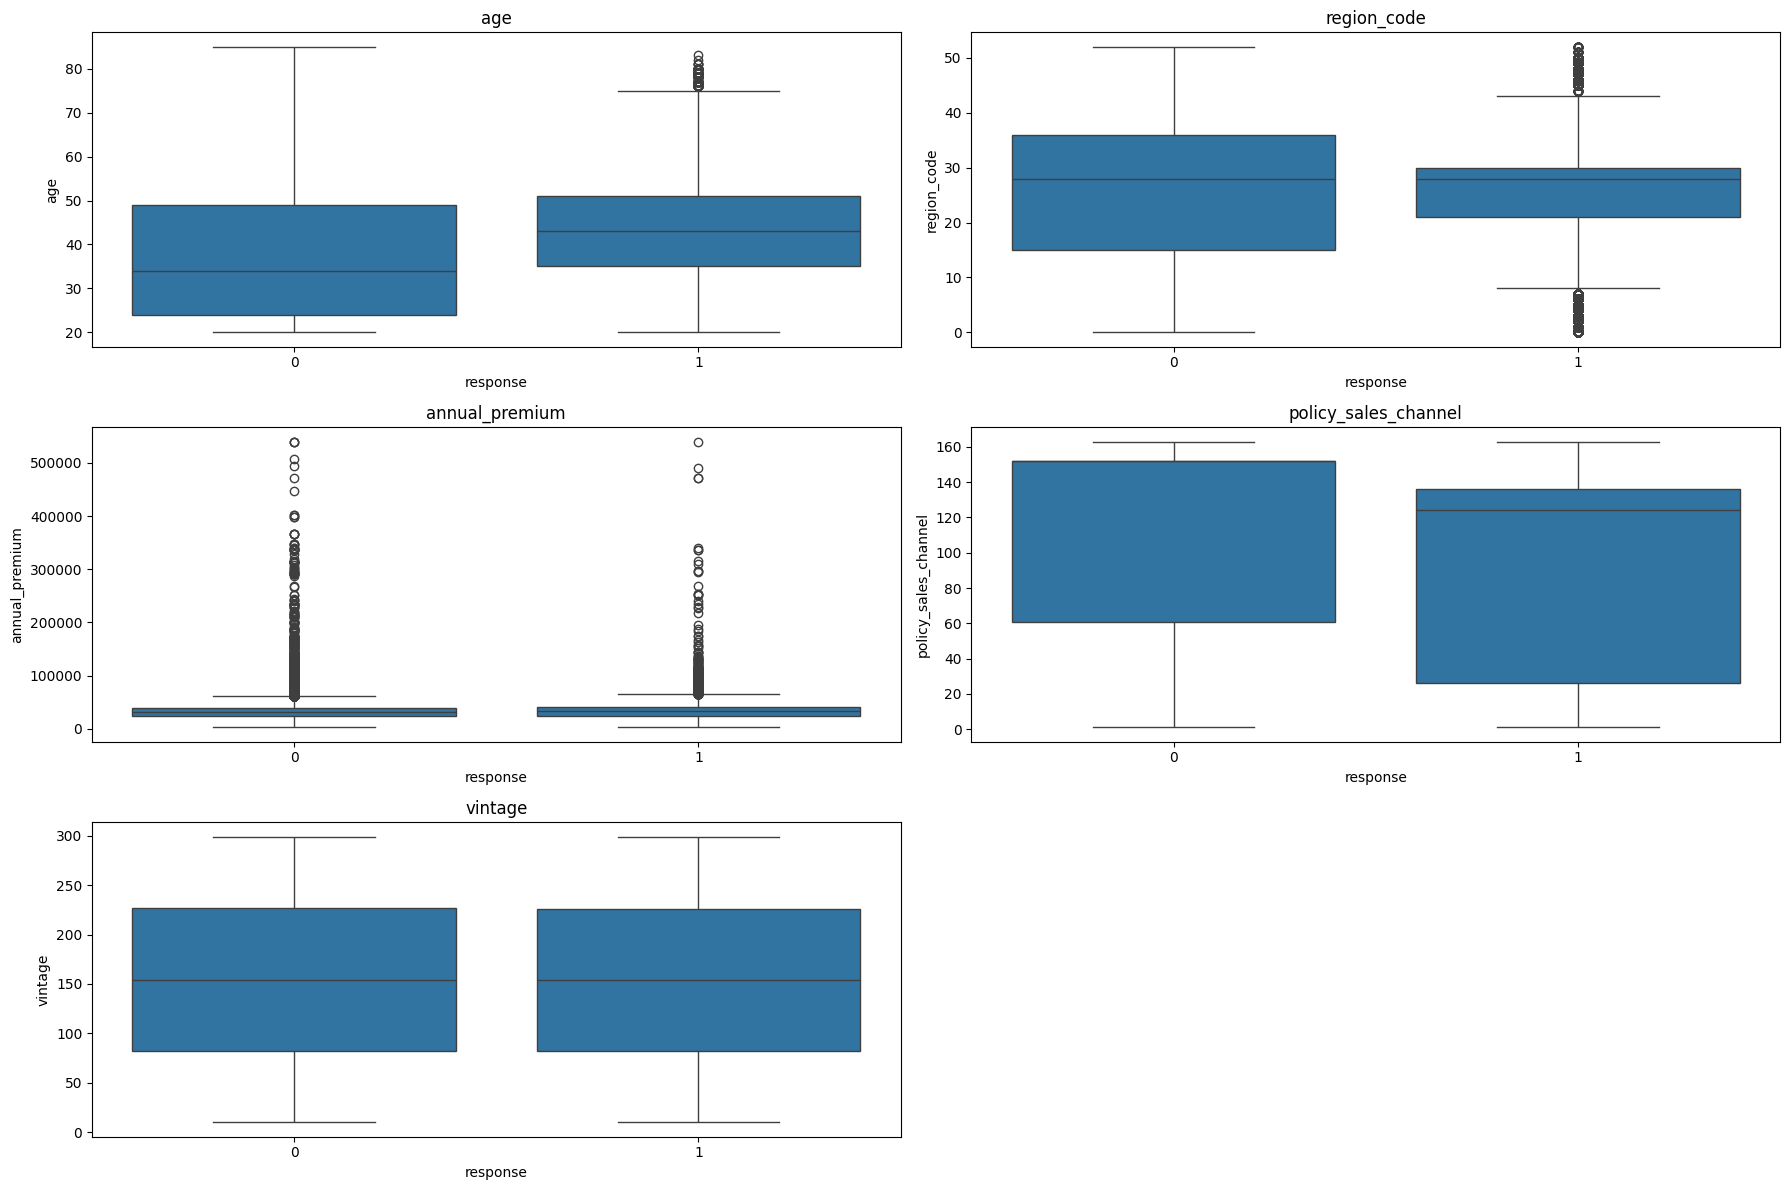

In [9]:
cols = [col for col in df_num_attributes.columns if col not in ['response']]

n_cols = 2
n_rows = (len(cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.boxplot(data=data, x='response', y=col, ax=axes[i])
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Insights — Numerical Variables:**
1. **`age`**: Interested clients (response=1) are older on average (~43 vs ~34). Older people value insurance more.
2. **`vintage`**: Identical distribution across both classes — no predictive power. Will be dropped.
3. **`annual_premium`**: Very similar medians between classes — low discriminative power.
4. **`region_code`**: Nearly identical distributions — region does not influence purchase decision.
5. **`policy_sales_channel`**: Slight difference — some channels convert better than others. Worth investigating.

### 4.2 Age — Deeper Analysis

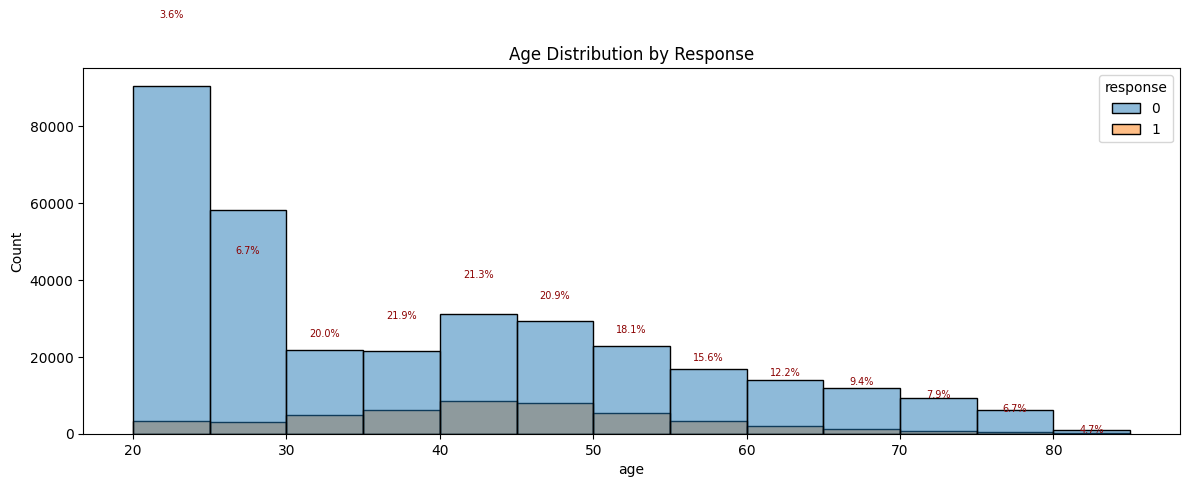

In [10]:
fig, axes = plt.subplots(1, 1, figsize=(12, 5))

bins = range(data['age'].min(), data['age'].max() + 5, 5)
sns.histplot(data=data, x='age', hue='response', bins=bins, ax=axes)
axes.set_title('Age Distribution by Response')

# Compute response=1 rate per age bin
data['age_bin'] = pd.cut(data['age'], bins=bins)
pct_by_bin = data.groupby('age_bin')['response'].mean() * 100

for age_bin, pct in pct_by_bin.items():
    x_mid = (age_bin.left + age_bin.right) / 2
    y_pos = data[data['age_bin'] == age_bin].shape[0]
    axes.text(x_mid, y_pos + 1, f'{pct:.1f}%', ha='center', fontsize=7, color='darkred')

plt.tight_layout()
plt.show()

**Insights — Age:**
- Ages 20–25: only 3.6% interest (largest group but lowest propensity).
- Interest grows from 25 to 40 years old, reaching ~21%.
- **Sweet spot: 35–50 years** — high conversion rate (~20%) with good volume.
- After 50, interest declines progressively down to 4.2% at 80+.

### 4.3 Policy Sales Channel — Deeper Analysis

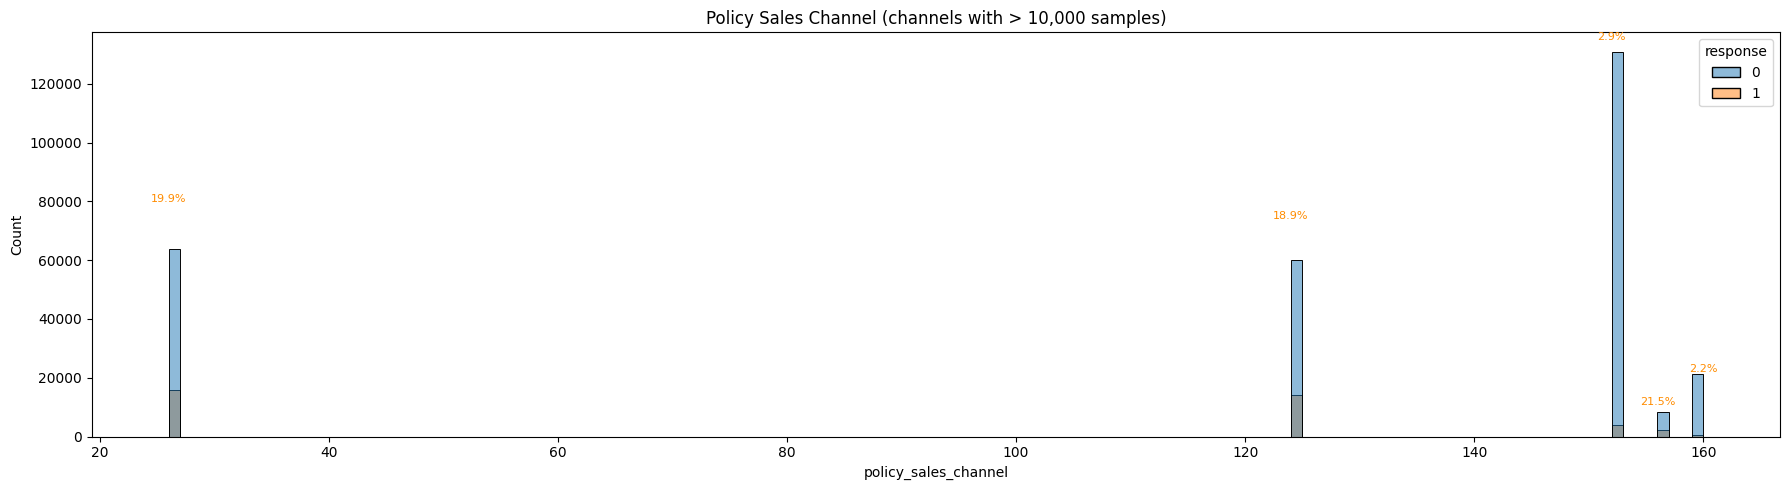

In [11]:
# Show only channels with more than 10,000 samples to reduce noise
top_channels = data['policy_sales_channel'].value_counts()
top_channels = top_channels[top_channels > 10000].index
df_filtered = data[data['policy_sales_channel'].isin(top_channels)]

fig, ax = plt.subplots(figsize=(18, 5))
sns.histplot(data=df_filtered, x='policy_sales_channel', hue='response', binwidth=1, ax=ax)
ax.set_title('Policy Sales Channel (channels with > 10,000 samples)')

pct_by_channel = df_filtered.groupby('policy_sales_channel')['response'].mean() * 100
for channel, pct in pct_by_channel.items():
    total = df_filtered[df_filtered['policy_sales_channel'] == channel].shape[0]
    ax.text(channel, total + 100, f'{pct:.1f}%', ha='center', fontsize=8, color='darkorange')

plt.tight_layout()
plt.show()

**Insights — Policy Sales Channel:**
- Two clear groups: channels 26, 124, 156 convert ~20% (likely active channels: agents/phone).
- Channels 152 and 160 convert <3% (likely passive channels: email/digital).

### 4.4 Categorical Variables — Count Plots

In [ ]:
cols = [col for col in df_cat_attributes.columns if col != 'response']

n_cols = 2
n_rows = (len(cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(cols):
    ax = axes[i]
    sns.countplot(data=data, x=col, hue='response', ax=ax)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=45)

    totals = data.groupby(col)['response'].count()

    for bar in ax.patches:
        height = bar.get_height()
        if height == 0:
            continue
        x_pos = bar.get_x() + bar.get_width() / 2
        category = ax.get_xticklabels()[round(bar.get_x())]
        category_label = category.get_text()
        if category_label in totals.index:
            pct = height / totals[category_label] * 100
            ax.text(x_pos, height + 0.5, f'{pct:.1f}%', ha='center', va='bottom', fontsize=9)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Insights — Categorical Variables:**
1. **`vehicle_damage`**: Clients with prior damage convert at 23.8% vs only 0.5% without. Strongest predictor.
2. **`previously_insured`**: Already-insured clients show near-zero interest — can be filtered out before calling.
3. **`vehicle_age`**: 1–2 year old vehicles have the highest interest (17.4%). Very new (<1 year) show only 4.4%.
4. **`gender`**: Minimal difference (13.8% vs 10.4%) — low discriminative power, likely to be dropped.

---
## 5. Feature Engineering

In [ ]:
df2 = data.copy()

# Drop low-predictive-power columns
# - vintage: identical distribution for response 0 and 1
# - age_bin: derived column used only for EDA visualization
# - driving_license: almost no samples with 'No'
# - region_code: low discriminative power and is categorical by nature
# - annual_premium: similar distributions across both classes
cols_to_drop = ['vintage', 'age_bin', 'driving_license', 'region_code', 'annual_premium']
df2 = df2.drop(columns=cols_to_drop)

print(list(df2.columns))

['gender', 'age', 'previously_insured', 'vehicle_age', 'vehicle_damage', 'policy_sales_channel', 'response']


In [ ]:
# Encode categorical columns to numerical
df2['vehicle_damage']    = df2['vehicle_damage'].apply(lambda x: 1 if x == 'Yes' else 0)
df2['previously_insured']= df2['previously_insured'].apply(lambda x: 1 if x == 'Yes' else 0)
df2['gender']            = df2['gender'].apply(lambda x: 1 if x == 'Female' else 0)

# Rename vehicle_age categories for cleaner column names after One Hot Encoding
df2['vehicle_age'] = df2['vehicle_age'].apply(
    lambda x: 'over_2_years'      if x == '> 2 Years' else
              'between_1_2_year'  if x == '1-2 Year'  else
              'below_1_year'
)

df2.head()

,gender,age,previously_insured,vehicle_age,vehicle_damage,policy_sales_channel,response
0,0,44,0,over_2_years,1,26,1
1,0,76,0,between_1_2_year,0,26,0
2,0,47,0,over_2_years,1,26,1
3,0,21,1,below_1_year,0,152,0
4,1,29,1,below_1_year,0,152,0


---
## 6. Data Preparation

### 6.1 Train / Validation / Test Split

In [ ]:
df3 = df2.copy()

X = df3.drop('response', axis=1)
y = df3['response'].copy()

x_train_val, x_test, y_train_val, y_test     = ms.train_test_split(X, y, test_size=0.25, random_state=42)
x_train, x_validation, y_train, y_validation = ms.train_test_split(x_train_val, y_train_val, test_size=0.3, random_state=42)

df_train = pd.concat([x_train, y_train], axis=1)

print(f"Train:      {x_train.shape[0]:,} samples | {x_train.shape[1]} features")
print(f"Validation: {x_validation.shape[0]:,} samples | {x_validation.shape[1]} features")
print(f"Test:       {x_test.shape[0]:,} samples | {x_test.shape[1]} features")

Train:      200,081 samples | 6 features
Validation: 85,750 samples | 6 features
Test:       95,278 samples | 6 features


### 6.2 Rescaling and Encoding

In [ ]:
# --- TRAIN ---

# age: MinMaxScaler (fit on train, apply to all sets)
mms_age = pp.MinMaxScaler()
df_train['age'] = mms_age.fit_transform(df_train[['age']].values).astype(float)
pickle.dump(mms_age, open('../src/features/age_scaler.pkl', 'wb'))

# vehicle_age: One Hot Encoding
# Note: no need to save — transformation is deterministic (fixed category names)
df_train = pd.get_dummies(df_train, prefix='vehicle_age', columns=['vehicle_age'])

# policy_sales_channel: Frequency Encoding
# Save the mapping to avoid data leakage on validation/test
fe_policy_sales_channel = df_train.groupby('policy_sales_channel').size() / len(df_train)
df_train['policy_sales_channel'] = df_train['policy_sales_channel'].map(fe_policy_sales_channel).astype(float)
pickle.dump(fe_policy_sales_channel, open('../src/features/fe_policy_sales_channel_scaler.pkl', 'wb'))

df_train.head()

,gender,age,previously_insured,vehicle_damage,policy_sales_channel,response,vehicle_age_below_1_year,vehicle_age_between_1_2_year,vehicle_age_over_2_years
8472,1,0.384615,0,1,0.015719,1,False,True,False
165195,1,0.076923,1,0,0.353677,0,True,False,False
30268,0,0.061538,1,0,0.353677,0,True,False,False
6777,1,0.307692,0,1,0.194376,0,False,True,False
258204,1,0.015385,0,1,0.353677,0,True,False,False


In [ ]:
def apply_encoding(df, mms_age, fe_policy_sales_channel):
    """Applies the same transformations learned from train to validation/test sets."""
    df = df.copy()
    df['age'] = df['age'].astype(float)
    df['age'] = mms_age.transform(df[['age']].values).flatten()
    df = pd.get_dummies(df, prefix='vehicle_age', columns=['vehicle_age'])
    df['policy_sales_channel'] = df['policy_sales_channel'].astype(float)
    df['policy_sales_channel'] = df['policy_sales_channel'].map(fe_policy_sales_channel)
    return df

# --- VALIDATION ---
x_validation = apply_encoding(x_validation, mms_age, fe_policy_sales_channel)

# --- TEST ---
x_test = apply_encoding(x_test, mms_age, fe_policy_sales_channel)

---
## 7. Feature Selection

### 7.1 Boruta Algorithm
> Boruta was tested but only selected `vehicle_damage` (likely due to class imbalance: 87.7% vs 12.3%).  
> We proceeded with feature importance from ExtraTreesClassifier instead.

In [ ]:
# Boruta result was unreliable — commented out for reference
# Class imbalance (87.7% / 12.3%) caused the model to learn trivial solutions

# import boruta as bt
# x_train_n = df_train.drop(['response'], axis=1).values
# y_train_n = y_train.values.ravel()
# et_boruta = en.ExtraTreesClassifier(n_jobs=-1, class_weight='balanced')
# boruta = bt.BorutaPy(et_boruta, n_estimators='auto', verbose=2, random_state=42).fit(x_train_n, y_train_n)
# cols_selected_boruta = df_train.drop(['response'], axis=1).iloc[:, boruta.support_].columns.tolist()
# print('Selected columns:', cols_selected_boruta)
print('Boruta skipped — see comment above.')

Boruta skipped — see comment above.


### 7.2 ExtraTreesClassifier — Feature Importance

                     feature  importance
              vehicle_damage    0.289500
          previously_insured    0.216530
                         age    0.196494
        policy_sales_channel    0.190759
    vehicle_age_below_1_year    0.057821
vehicle_age_between_1_2_year    0.032873
    vehicle_age_over_2_years    0.011501
                      gender    0.004521


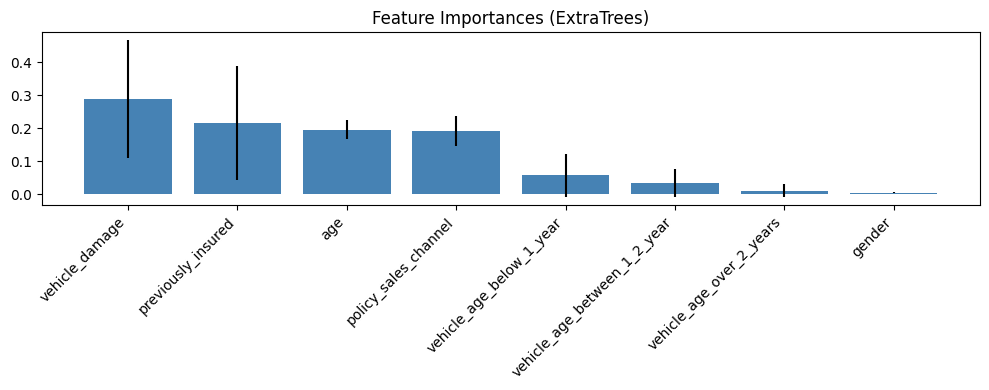

In [ ]:
x_train_n = df_train.drop(['response'], axis=1)
y_train_n = y_train.values

forest = en.ExtraTreesClassifier(n_estimators=250, random_state=0, n_jobs=-1)
forest.fit(x_train_n, y_train_n)

importances = forest.feature_importances_
std     = np.std([tree.feature_importances_ for tree in forest.estimators_], axis=0)
indices = np.argsort(importances)[::-1]

# Feature importance table
df_importance = pd.DataFrame({
    'feature': x_train_n.columns,
    'importance': importances
}).sort_values('importance', ascending=False)

print(df_importance.to_string(index=False))

# Feature importance bar chart
plt.figure(figsize=(10, 4))
plt.title('Feature Importances (ExtraTrees)')
plt.bar(range(x_train_n.shape[1]), importances[indices], color='steelblue', yerr=std[indices], align='center')
plt.xticks(range(x_train_n.shape[1]), x_train_n.columns[indices], rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Feature Importance Results:**
- **High relevance**: `vehicle_damage` (30%), `previously_insured` (21%), `age` (20%), `policy_sales_channel` (19%)
- **Medium relevance**: `vehicle_age_*` features (~10% combined)
- **Low relevance**: `gender` (0.36%) → dropped

Decision: keep all features except `gender`.

---
## 8. Machine Learning Models

In [ ]:
# Remove gender from all sets
x_train = df_train.drop(columns=['response', 'gender']).reset_index(drop=True)
y_train = df_train['response'].reset_index(drop=True)

# Validation — drop NaNs (from frequency encoding unmapped channels) and gender
df_validation = pd.concat([x_validation, y_validation], axis=1).dropna().reset_index(drop=True)
x_val = df_validation.drop(columns=['response', 'gender'])
y_val = df_validation['response']

# Test — same cleanup
df_test = pd.concat([x_test, y_test], axis=1).dropna().reset_index(drop=True)
x_test  = df_test.drop(columns=['response', 'gender'])
y_test  = df_test['response']

print(f"x_train shape: {x_train.shape}")
print(f"x_val   shape: {x_val.shape}")
print(f"x_test  shape: {x_test.shape}")

x_train shape: (200081, 7)
x_val   shape: (85747, 7)
x_test  shape: (95272, 7)


### 8.1 KNN Classifier

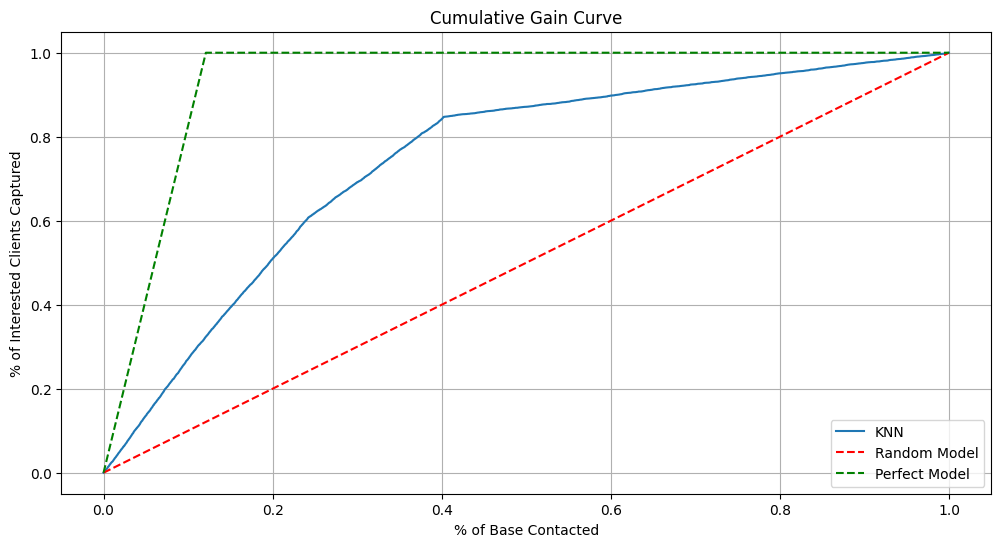

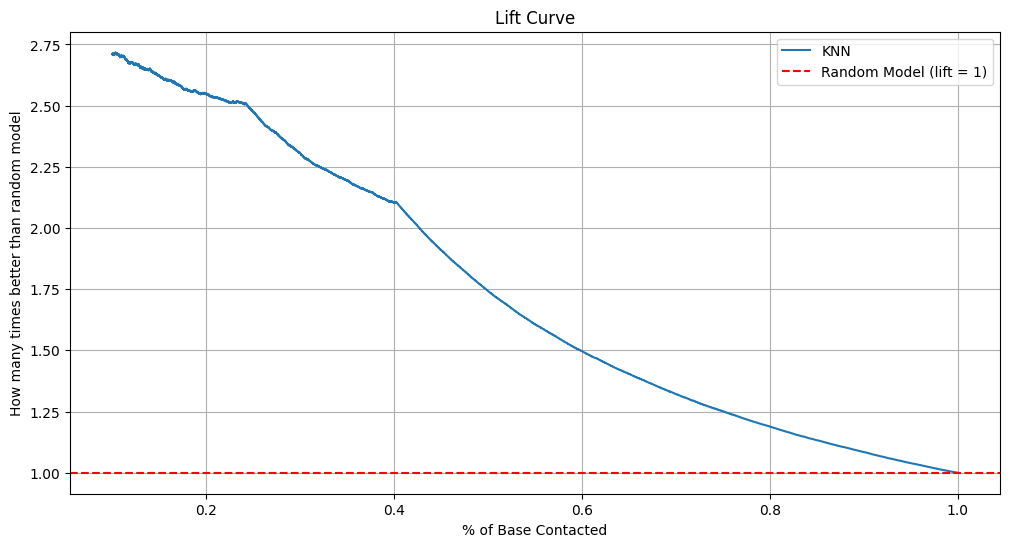

In [ ]:
knn_model = nh.KNeighborsClassifier(n_neighbors=7)
knn_model.fit(x_train, y_train)
yhat_knn = knn_model.predict_proba(x_val)

plot_cumulative_gain(y_val, {'KNN': yhat_knn})
plot_lift_curve(y_val, {'KNN': yhat_knn})

### 8.2 Logistic Regression

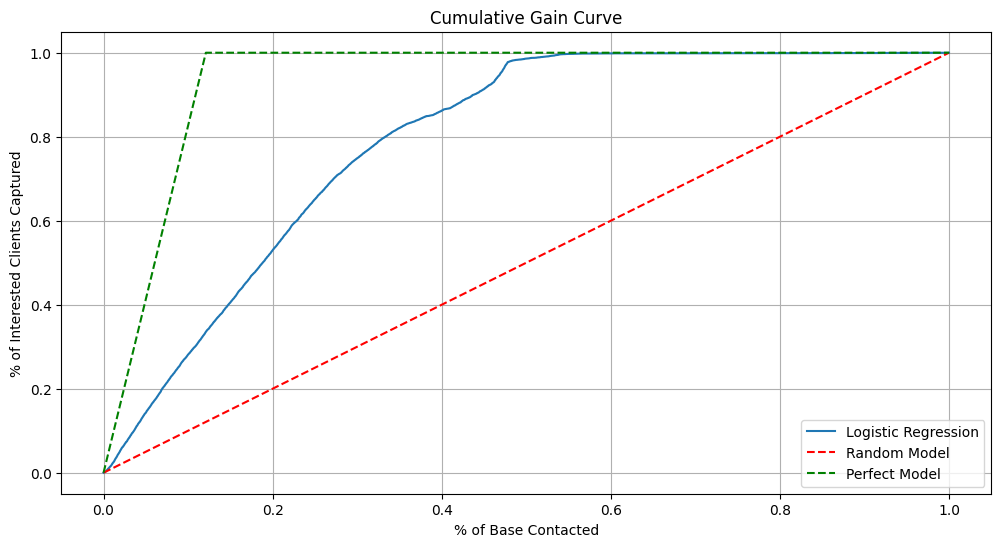

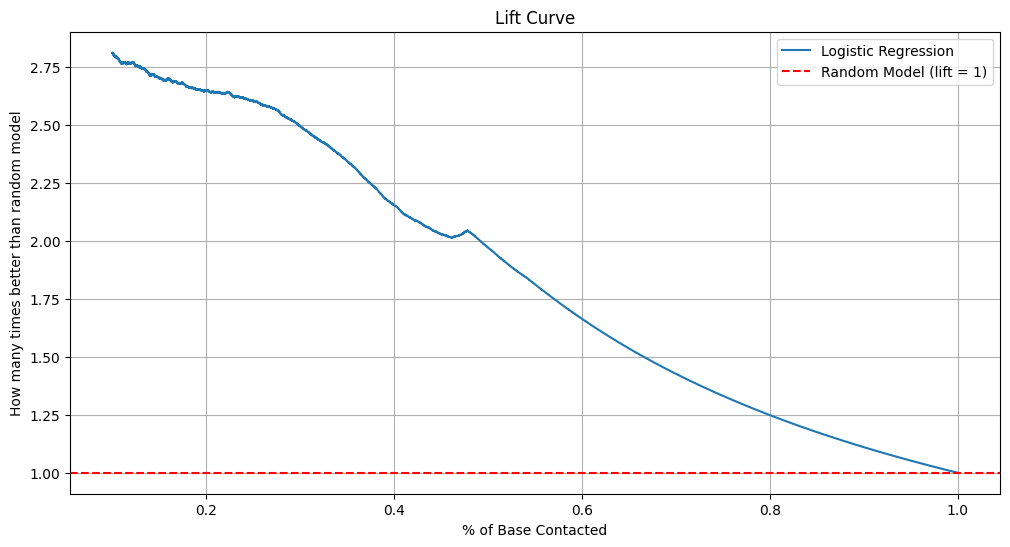

In [ ]:
lr_model = lm.LogisticRegression(random_state=42)
lr_model.fit(x_train, y_train)
yhat_lr = lr_model.predict_proba(x_val)

plot_cumulative_gain(y_val, {'Logistic Regression': yhat_lr})
plot_lift_curve(y_val, {'Logistic Regression': yhat_lr})

### 8.3 Extra Trees Classifier

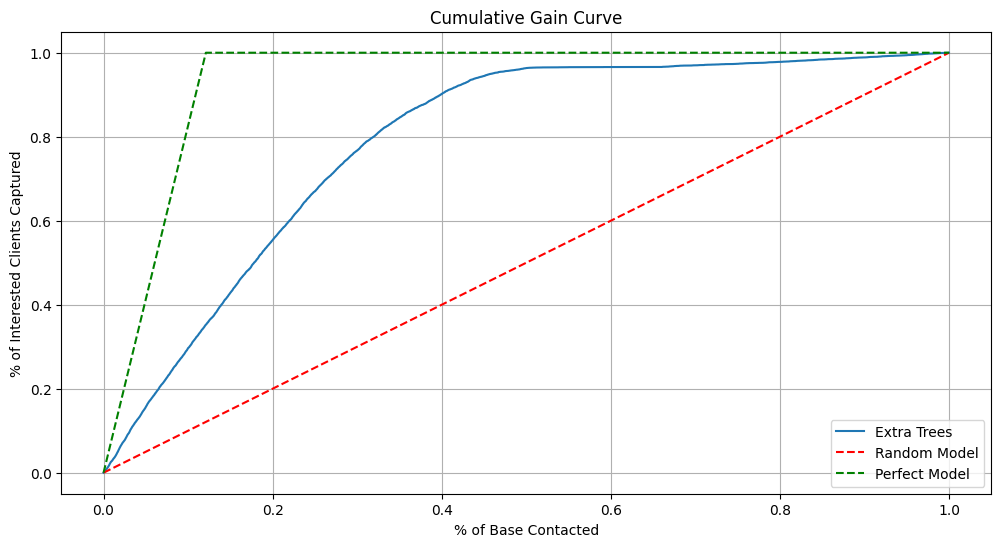

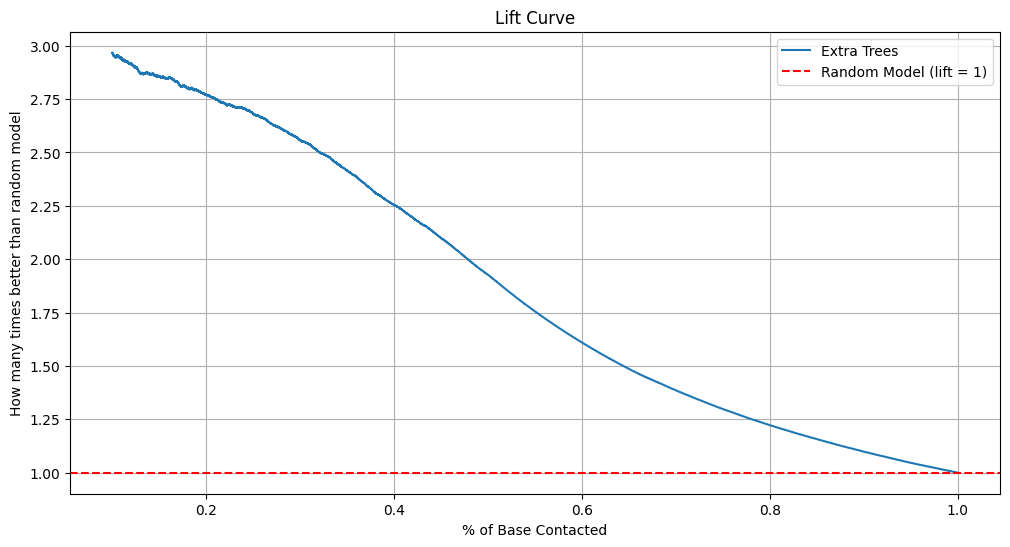

In [ ]:
et_model = en.ExtraTreesClassifier(n_estimators=1000, n_jobs=-1, random_state=42)
et_model.fit(x_train, y_train)
yhat_et = et_model.predict_proba(x_val)

plot_cumulative_gain(y_val, {'Extra Trees': yhat_et})
plot_lift_curve(y_val, {'Extra Trees': yhat_et})

### 8.4 Random Forest

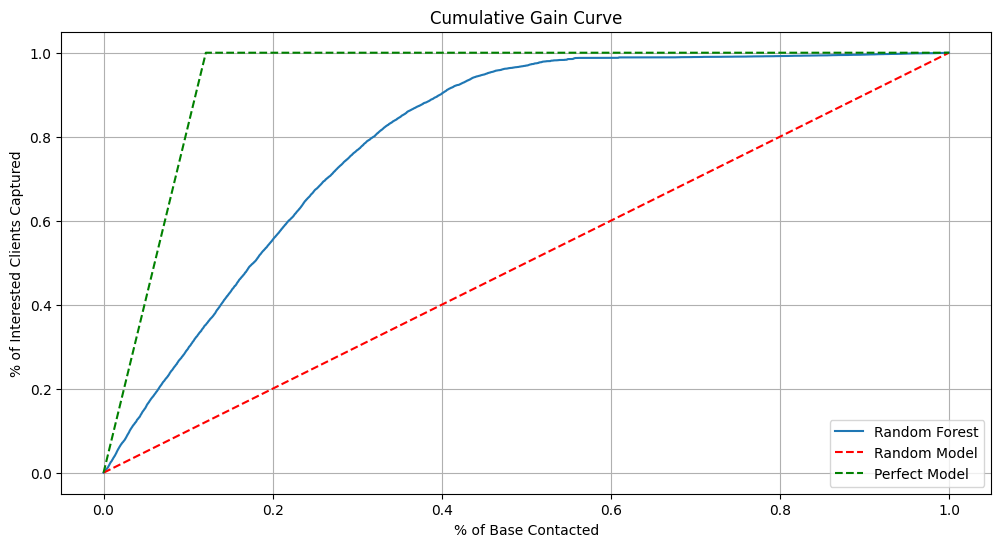

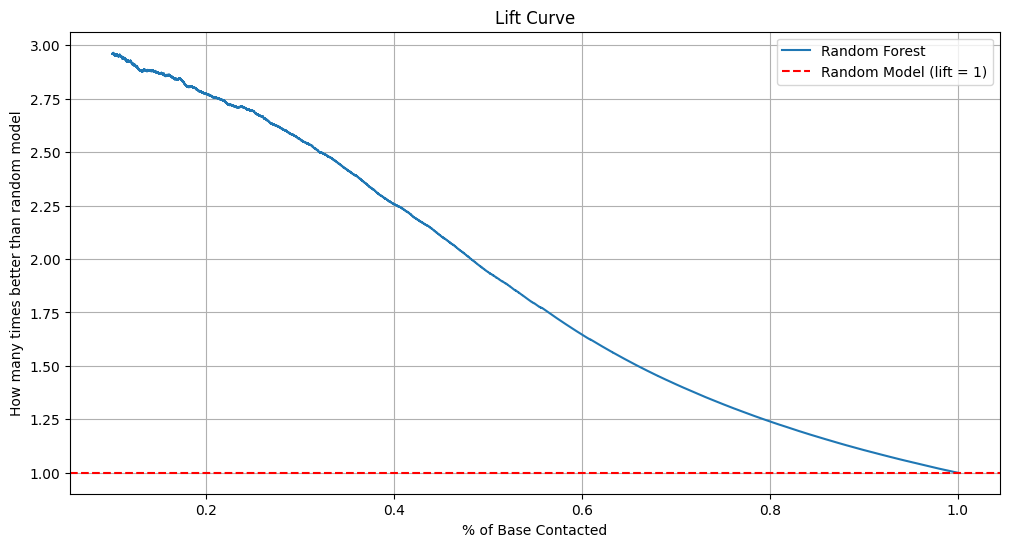

In [ ]:
rf_model = en.RandomForestClassifier(n_estimators=1000, n_jobs=-1, random_state=42)
rf_model.fit(x_train, y_train)
yhat_rf = rf_model.predict_proba(x_val)

plot_cumulative_gain(y_val, {'Random Forest': yhat_rf})
plot_lift_curve(y_val, {'Random Forest': yhat_rf})

### 8.5 Model Comparison

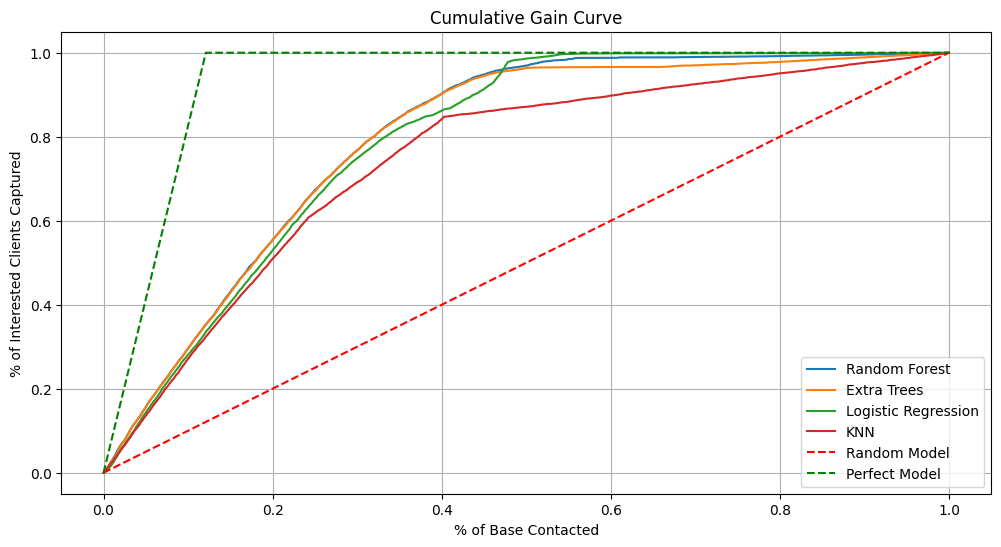

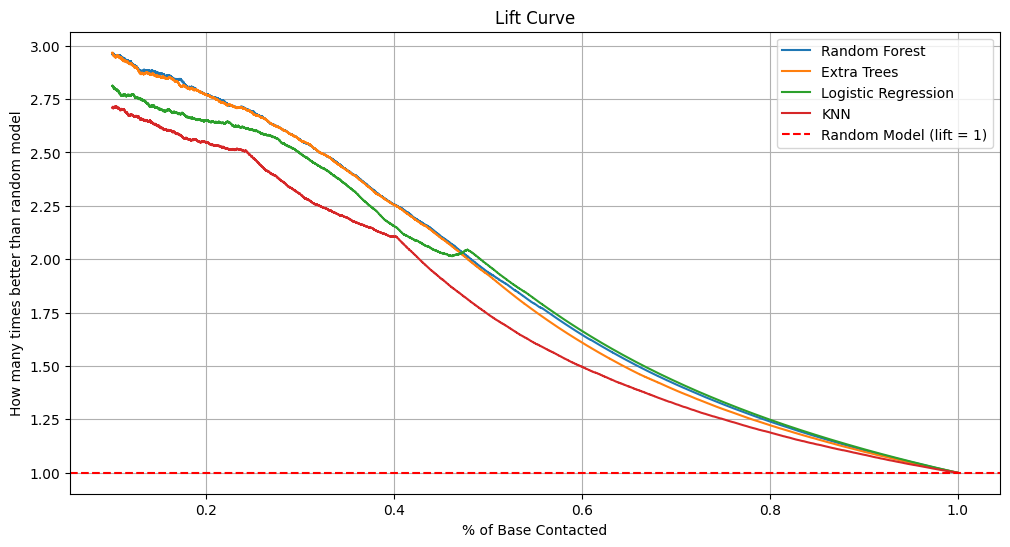

In [ ]:
yhats = {
    'Random Forest':       yhat_rf,
    'Extra Trees':         yhat_et,
    'Logistic Regression': yhat_lr,
    'KNN':                 yhat_knn
}

plot_cumulative_gain(y_val, yhats)
plot_lift_curve(y_val, yhats)

---
## 9. Final Model — Random Forest on Full Train+Validation

Random Forest was selected as the final model.  
We now retrain on **train + validation** combined to maximize data usage before evaluating on the held-out test set.

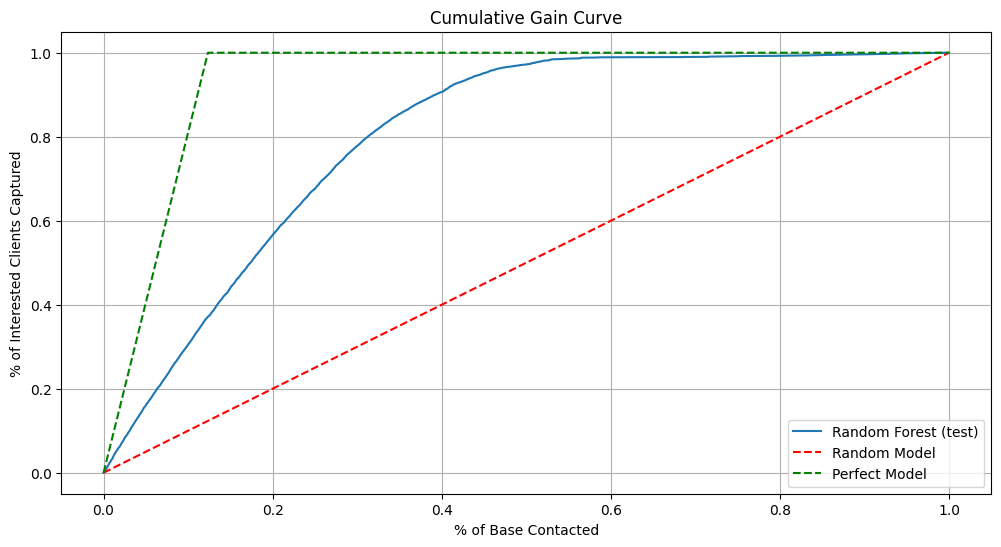

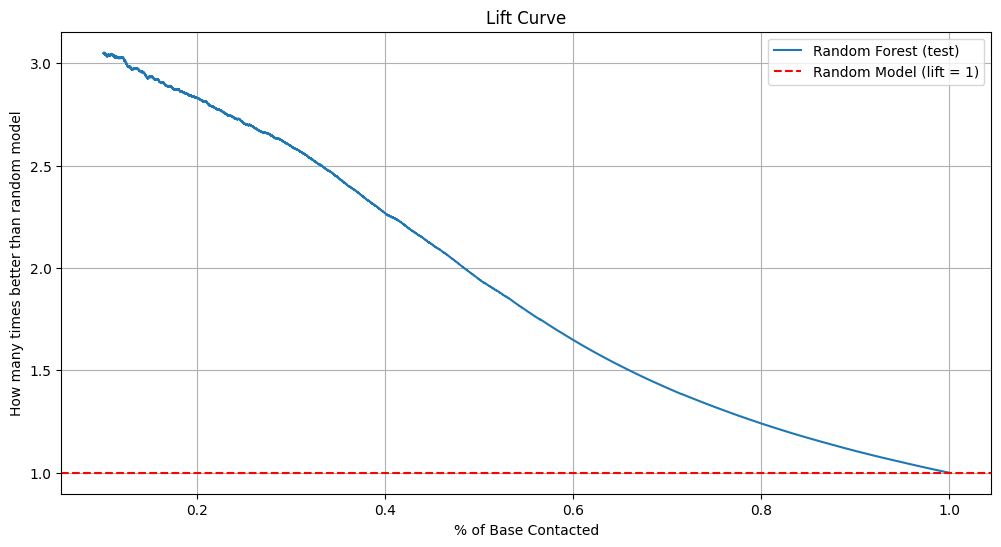

In [ ]:
# Combine train and validation sets
x_train_full = pd.concat([x_train, x_val]).reset_index(drop=True)
y_train_full = pd.concat([y_train, y_val]).reset_index(drop=True)

# Retrain on full dataset
rf_final = en.RandomForestClassifier(n_estimators=1000, n_jobs=-1, random_state=42)
rf_final.fit(x_train_full, y_train_full)

# Predict on test set
yhat_rf_test = rf_final.predict_proba(x_test)

plot_cumulative_gain(y_test, {'Random Forest (test)': yhat_rf_test})
plot_lift_curve(y_test, {'Random Forest (test)': yhat_rf_test})

---
## 10. Business Performance (ROI)

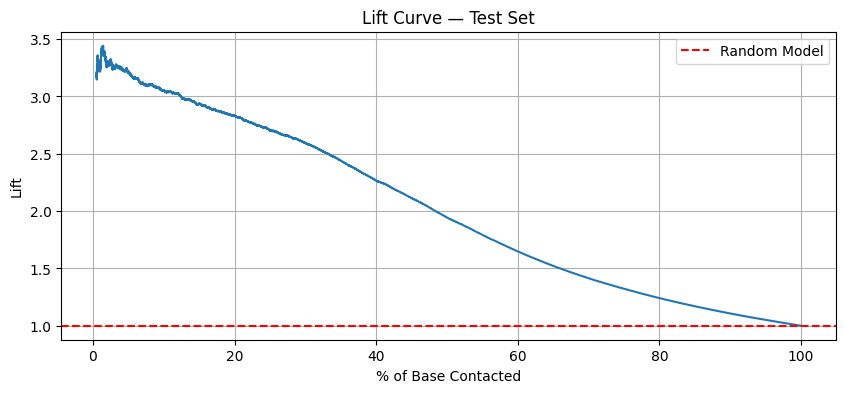

In [ ]:
results = pd.DataFrame()
results['prediction'] = yhat_rf_test[:, 1].tolist()
results['real']       = y_test.tolist()

# Sort by predicted probability (descending)
results = results.sort_values('prediction', ascending=False).reset_index(drop=True)

# Cumulative gain metrics
results['real_cum']      = results['real'].cumsum()
results['real_cum_perc'] = 100 * results['real_cum'] / results['real'].sum()

# Base coverage metrics
results['base']          = range(1, len(results) + 1)
results['base_cum_perc'] = 100 * results['base'] / len(results)

# Lift
results['lift'] = results['real_cum_perc'] / results['base_cum_perc']

# Lift curve 
plt.figure(figsize=(10, 4))
sns.lineplot(x='base_cum_perc', y='lift', data=results[results['base_cum_perc'] >= 0.5])
plt.axhline(y=1, color='red', linestyle='--', label='Random Model')
plt.xlabel('% of Base Contacted')
plt.ylabel('Lift')
plt.title('Lift Curve — Test Set')
plt.grid(True)
plt.legend()
plt.show()

### 10.2 Revenue Simulation

We simulate expected financial return by grouping clients into probability buckets and applying simple cost/revenue assumptions.

**Column descriptions:**

- `bucket`: probability range the client falls into (grouped in 0.05 intervals). E.g., bucket 0.20 = clients with predicted propensity between 0.20 and 0.25.
- `propensity_score`: minimum predicted probability within that bucket — used as a conservative estimate of conversion rate.
- `clients`: number of clients in that bucket.
- `gross_revenue`: expected revenue if we call all clients in this bucket. Calculated as `R$40 × clients × propensity_score` (R$40 profit per successful sale).
- `cost`: total calling cost for the bucket. Calculated as `R$4 × clients` (R$4 cost per call regardless of outcome).
- `net_revenue`: gross_revenue minus cost — the actual expected profit from this bucket.
- `base_pct`: cumulative share of the total base covered up to this bucket, ordered from highest to lowest propensity.

In [ ]:
# Join predictions with real labels
results['bucket'] = results['prediction'].apply(lambda x: round(round(x, 2) - (round(x, 2) % 0.05), 2))

df_roi = results.groupby('bucket').agg(
    clients   = ('real', 'count'),
    converted = ('real', 'sum')   # actual number of interested clients in each bucket
).reset_index()

df_roi['gross_revenue'] = 40 * df_roi['converted']
df_roi['cost']          = 4  * df_roi['clients']
df_roi['net_revenue']   = df_roi['gross_revenue'] - df_roi['cost']
df_roi['propensity_score'] = df_roi['converted'] / df_roi['clients']  # real conversion rate per bucket

df_roi = df_roi.sort_values('bucket', ascending=False).reset_index(drop=True)
df_roi['base_pct'] = df_roi['clients'].cumsum() / df_roi['clients'].sum()

df_roi.head(20)

,bucket,clients,converted,gross_revenue,cost,net_revenue,propensity_score,base_pct
0,0.95,11,4,160,44,116,0.363636,0.000115
1,0.90,10,2,80,40,40,0.200000,0.000220
2,0.85,31,12,480,124,356,0.387097,0.000546
3,0.80,25,14,560,100,460,0.560000,0.000808
4,0.75,25,10,400,100,300,0.400000,0.001071
5,0.70,42,17,680,168,512,0.404762,0.001511
6,0.65,50,19,760,200,560,0.380000,0.002036
7,0.60,102,36,1440,408,1032,0.352941,0.003107
8,0.55,113,42,1680,452,1228,0.371681,0.004293
9,0.50,305,134,5360,1220,4140,0.439344,0.007494


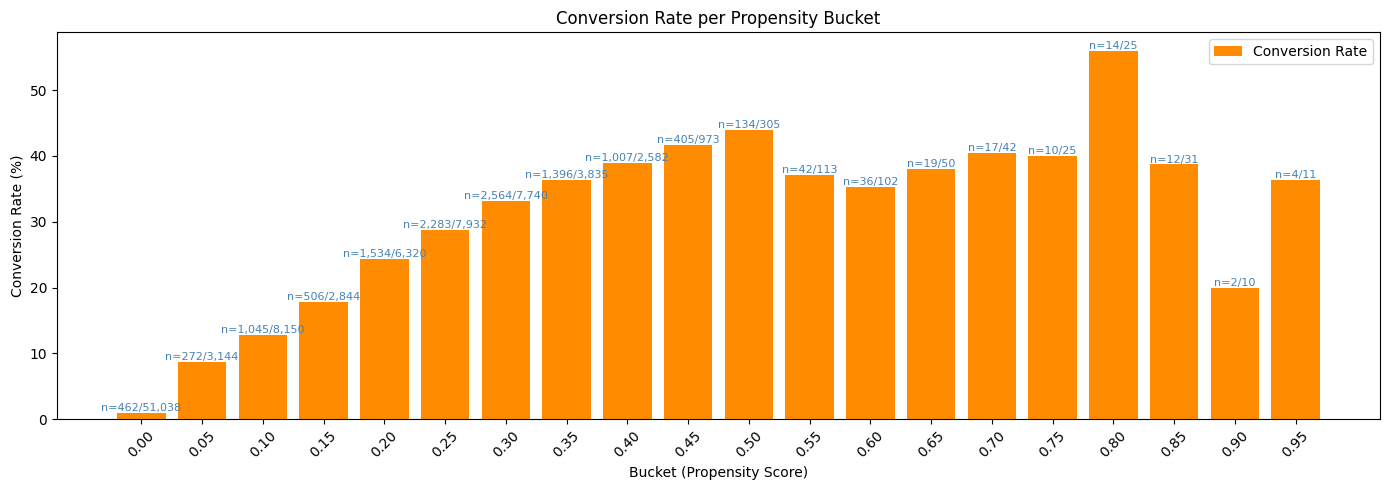

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))

df_plot = df_roi.sort_values('bucket', ascending=True)

x = np.arange(len(df_plot))

df_plot['conversion_rate'] = df_plot['converted'] / df_plot['clients'] * 100

bars = ax.bar(x, df_plot['conversion_rate'], color='darkorange', label='Conversion Rate')

# Label above each bar: converted / total
for bar, conv, total in zip(bars, df_plot['converted'], df_plot['clients']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'n={int(conv):,}/{int(total):,}', ha='center', fontsize=8, color='steelblue')

ax.set_xticks(x)
ax.set_xticklabels([f'{b:.2f}' for b in df_plot['bucket']], rotation=45)
ax.set_xlabel('Bucket (Propensity Score)')
ax.set_ylabel('Conversion Rate (%)')
ax.set_title('Conversion Rate per Propensity Bucket')
ax.legend()
plt.tight_layout()
plt.show()

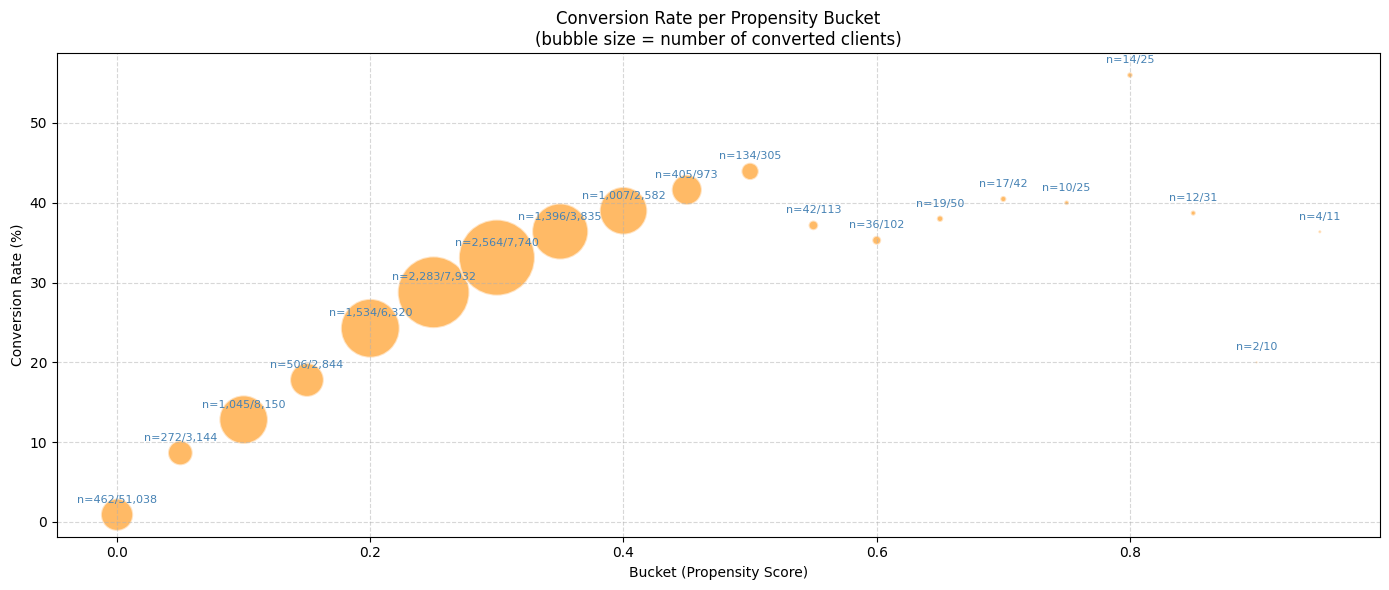

In [ ]:
fig, ax = plt.subplots(figsize=(14, 6))
df_roi['conversion_rate'] = df_roi['converted'] / df_roi['clients'] * 100
df_plot = df_roi.sort_values('bucket', ascending=True)

# Normalize bubble size for better visualization
bubble_size = df_plot['converted'] / df_plot['converted'].max() * 3000

scatter = ax.scatter(
    df_plot['bucket'],
    df_plot['conversion_rate'],
    s=bubble_size,
    color='darkorange',
    alpha=0.6,
    edgecolors='white',
    linewidth=1.5
)

# Label each bubble with converted/total
for _, row in df_plot.iterrows():
    ax.text(row['bucket'], row['conversion_rate'] + 1.5,
            f"n={int(row['converted']):,}/{int(row['clients']):,}",
            ha='center', fontsize=8, color='steelblue')

ax.set_xlabel('Bucket (Propensity Score)')
ax.set_ylabel('Conversion Rate (%)')
ax.set_title('Conversion Rate per Propensity Bucket\n(bubble size = number of converted clients)')
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

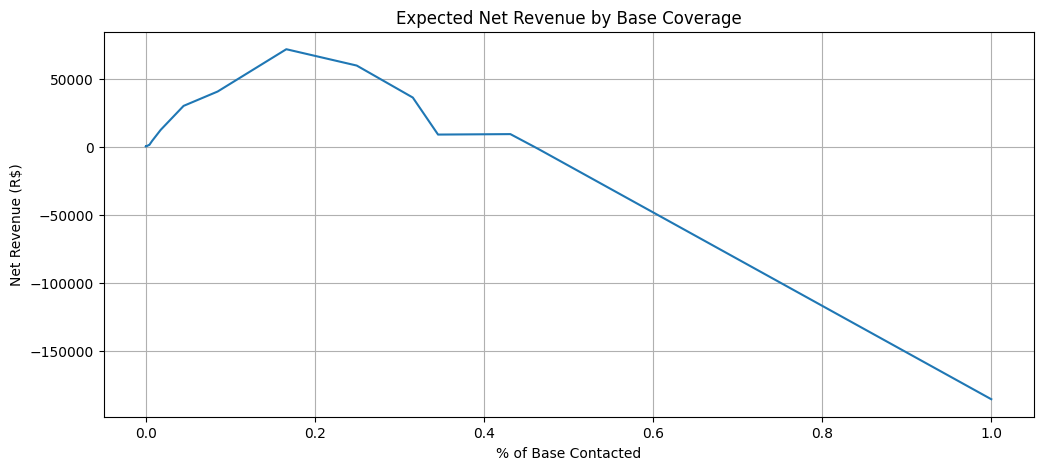

In [ ]:
# Revenue curve — only show buckets with propensity >= 10%
plt.figure(figsize=(12, 5))
aux = df_roi[df_roi['net_revenue'] >= -200000]
sns.lineplot(x='base_pct', y='net_revenue', data=aux)
plt.xlabel('% of Base Contacted')
plt.ylabel('Net Revenue (R$)')
plt.title('Expected Net Revenue by Base Coverage')
plt.grid(True)
plt.show()